# Week 3 - Task 5: Mini Project - Student Performance Prediction
**Goal:** predict whether a student will **Pass or Fail** from Study Hours, Attendance, Previous Marks and Assignment Score using a Machine Learning classification model (Logistic Regression).

## 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 120); pd.set_option('display.max_columns', 20)

df = pd.read_csv("Dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (204, 6)


   Student_ID  Study_Hours  Attendance  Previous_Marks  Assignment_Score Result
0        2173          5.3        82.0            27.0              68.0   Pass
1        2090          4.0        55.0            71.0              73.0   Pass
2        2056          1.2        90.0            66.0              70.0   Pass
3        2074          4.3        82.0            79.0              65.0   Pass
4        2159          3.4       100.0            42.0              60.0   Pass

## 2. Clean the data

In [2]:
print("Missing values:", df.isnull().sum().sum(), "| Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()                                   # remove duplicate records
num_cols = ["Study_Hours", "Attendance", "Previous_Marks", "Assignment_Score"]
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())              # fill missing values with median
df = df.reset_index(drop=True)

print("After cleaning -> Missing:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum(), "| Shape:", df.shape)
print()
print(df["Result"].value_counts())

Missing values: 21 | Duplicate rows: 4
After cleaning -> Missing: 0 | Duplicates: 0 | Shape: (200, 6)

Result
Pass    143
Fail     57
Name: count, dtype: int64


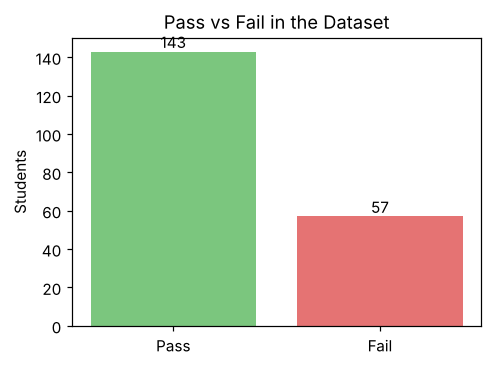

In [3]:
counts = df["Result"].value_counts()
plt.figure(figsize=(4.8, 3.4))
bars = plt.bar(counts.index, counts.values, color=["#7bc67e", "#e57373"])
plt.bar_label(bars)
plt.title("Pass vs Fail in the Dataset"); plt.ylabel("Students")
plt.show()

## 3. Select features and target

In [4]:
features = ["Study_Hours", "Attendance", "Previous_Marks", "Assignment_Score"]
X = df[features]
y = df["Result"]
print("Features:", features)
print("Target  : Result (Pass / Fail)")

Features: ['Study_Hours', 'Attendance', 'Previous_Marks', 'Assignment_Score']
Target  : Result (Pass / Fail)


## 4. Split into training and testing data

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training records:", len(X_train), "| Testing records:", len(X_test))

Training records: 160 | Testing records: 40


## 5. Train a classification model

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_s, y_train)
print("Logistic Regression model trained")

Logistic Regression model trained


## 6. Make predictions and calculate accuracy

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test_s)
print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print()
print("Confusion matrix [Fail, Pass]:")
print(confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"]))
print()
print(classification_report(y_test, y_pred))

Model Accuracy: 90.0 %

Confusion matrix [Fail, Pass]:
[[ 8  3]
 [ 1 28]]

              precision    recall  f1-score   support

        Fail       0.89      0.73      0.80        11
        Pass       0.90      0.97      0.93        29

    accuracy                           0.90        40
   macro avg       0.90      0.85      0.87        40
weighted avg       0.90      0.90      0.90        40



In [8]:
# Comparison with a second model (Decision Tree) to check that the result is reasonable
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print("Decision Tree accuracy      :", round(accuracy_score(y_test, tree.predict(X_test)) * 100, 2), "%")
print("Logistic Regression accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Decision Tree accuracy      : 85.0 %
Logistic Regression accuracy: 90.0 %


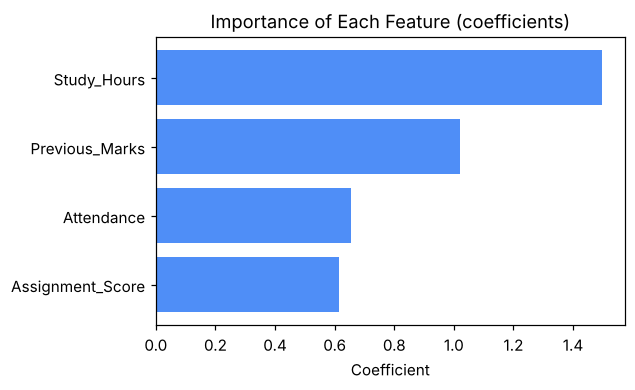

In [9]:
coef = pd.Series(model.coef_[0], index=features).sort_values()
plt.figure(figsize=(5.5, 3.4))
plt.barh(coef.index, coef.values, color="#4f8ef7")
plt.title("Importance of Each Feature (coefficients)"); plt.xlabel("Coefficient")
plt.show()

## 7. Test the model with new student inputs

In [10]:
def predict_student(study_hours, attendance, previous_marks, assignment_score):
    """Predict Pass/Fail for a new student."""
    student = pd.DataFrame([[study_hours, attendance, previous_marks, assignment_score]], columns=features)
    scaled = scaler.transform(student)
    result = model.predict(scaled)[0]
    p_pass = model.predict_proba(scaled)[0][list(model.classes_).index("Pass")]
    print(f"Study Hours: {study_hours} | Attendance: {attendance}% | Previous Marks: {previous_marks} | Assignment: {assignment_score}")
    print(f"Prediction: {result.upper()}  (probability of passing = {p_pass:.2f})\n")

predict_student(6, 85, 72, 70)    # strong student
predict_student(2, 55, 40, 35)    # weak student
predict_student(4, 70, 55, 60)    # average student
predict_student(8, 90, 80, 85)    # very hardworking student

Study Hours: 6 | Attendance: 85% | Previous Marks: 72 | Assignment: 70
Prediction: PASS  (probability of passing = 0.99)

Study Hours: 2 | Attendance: 55% | Previous Marks: 40 | Assignment: 35
Prediction: FAIL  (probability of passing = 0.01)

Study Hours: 4 | Attendance: 70% | Previous Marks: 55 | Assignment: 60
Prediction: PASS  (probability of passing = 0.54)

Study Hours: 8 | Attendance: 90% | Previous Marks: 80 | Assignment: 85
Prediction: PASS  (probability of passing = 1.00)



In [11]:
# Try your own input
hours = float(input("Study hours per day: "))
att = float(input("Attendance %: "))
prev = float(input("Previous marks: "))
assign = float(input("Assignment score: "))
predict_student(hours, att, prev, assign)

Study hours per day: 5
Attendance %: 75
Previous marks: 62
Assignment score: 58
Study Hours: 5.0 | Attendance: 75.0% | Previous Marks: 62.0 | Assignment: 58.0
Prediction: PASS  (probability of passing = 0.85)



## 8. Project Report
**Dataset used:** A student performance dataset (`Dataset.csv`) with 204 records. After removing 4 duplicate rows and filling 21 missing values with the median, 200 students remained. About 72% of them passed.

**Features selected:** Study Hours, Attendance, Previous Marks and Assignment Score. The target is `Result` (Pass/Fail). Student ID was ignored because it is only an identifier.

**Model used:** Logistic Regression, a classification algorithm that outputs the probability of passing. The data was split 80/20 (160 training, 40 testing records) and the features were scaled with StandardScaler.

**Results and accuracy:** The model reached **90% accuracy** on the test data, correctly predicting 36 of 40 students. It found 28 of 29 passing students but only 8 of 11 failing students. A Decision Tree gave 85%, so Logistic Regression was kept. For new students it predicted PASS for (6 hrs, 85%, 72 marks, 70 assignment) and FAIL for (2 hrs, 55%, 40 marks, 35 assignment).

**Limitations:** The dataset is small and was prepared for practice, so real results may differ. The test set has only 40 students, so accuracy can change with a different split. Fewer failing students means weaker detection of "Fail", and only four features are used.

**Future improvements:** Use a larger real dataset, add features such as class participation, use cross-validation, handle class imbalance, compare Random Forest, and build a small web app for predictions.